# Experiment 2 — Budget Sensitivity of Minimax Verification

**Notebook status:** executable pipeline-validation notebook using the historical `reference-50-v1` Development evaluation.

> **Scientific-use warning:** this artifact is a historical reference study, not a confirmed Experiment 2 dataset/specification. Results produced here must be labelled *historical Development pipeline validation*, not new Experiment 2 findings. Obtain the team's approval of the dataset, primary specification, and budget levels before treating any output as Experiment 2 evidence.

This notebook:
- loads only the historical **History** and **Development** inputs needed by the fitting/restriction workflow;
- does not release, inspect, or evaluate the reserved Final Test examples;
- uses the repository's `restrict_budget_evaluation()` and `build_policy()` implementations;
- solves a separate minimax policy at each selected budget;
- exports strategy probabilities, verifier inclusion probabilities, and Development loss/coverage summaries.

It does **not** rerun verifier executions. The budget restriction reuses the finalized Development payoff evaluation and removes strategies that exceed each budget. Estimated verifier costs are not observed request latency. No latency distribution is inferred from these artifacts.


## 1. Environment and imports

Run this notebook from the repository root, or change `REPO_ROOT` below. Install the repository's declared dependencies in the active Jupyter kernel before continuing if imports fail.

In [1]:
from pathlib import Path
import json
import sys
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Change this if the notebook is not running from the repository root.
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "app" / "game").exists():
    raise FileNotFoundError(
        "Run this notebook with the capstone-backend repository as the working directory, "
        "or set REPO_ROOT to that directory."
    )

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from app.game.models import PlanningContext
from app.game.offline.records import TrainingManifest
from app.game.offline.evaluation import Evaluation, bind_evaluation
from app.game.offline.replay import category_id
from app.game.offline.budget_sensitivity import restrict_budget_evaluation
from app.game.task_conditioning import bind_task_history

ARTIFACT_DIR = (
    REPO_ROOT
    / "artifacts"
    / "remaining-category-studies-v1"
    / "reference-50-v1"
    / "fit"
)

CONTEXT_PATH = ARTIFACT_DIR / "context.json"
MANIFEST_PATH = ARTIFACT_DIR / "training-manifest.json"
EVALUATION_PATH = ARTIFACT_DIR / "development-evaluation.json"

for path in (CONTEXT_PATH, MANIFEST_PATH, EVALUATION_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required historical pipeline-validation input missing: {path}")

print("Repository:", REPO_ROOT)
print("Artifact directory:", ARTIFACT_DIR)


C:\Users\user\Desktop\Capstone stuff\capstone-backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: C:\Users\user\Desktop\Capstone stuff\capstone-backend
Artifact directory: C:\Users\user\Desktop\Capstone stuff\capstone-backend\artifacts\remaining-category-studies-v1\reference-50-v1\fit


## 2. Load and verify historical Development inputs

The `TrainingManifest` contains History and Development partitions plus a Final Test reservation. The notebook verifies the partition roles and only reports the History/Development counts. It deliberately does not inspect or load any reserved Final Test example payload into the analysis.

In [2]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


context_raw = json.loads(CONTEXT_PATH.read_text(encoding="utf-8"))
manifest_raw = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
evaluation_raw = json.loads(EVALUATION_PATH.read_text(encoding="utf-8"))

# The saved evaluation predates the later policy constraints.
# Reconstruct its compatible source context in memory only.
# Do not modify context.json or any source artifact.
context_raw["clean_coverage_json"] = None
context_raw["reliability_first_json"] = None

context = PlanningContext.model_validate(context_raw)
manifest = TrainingManifest.model_validate(manifest_raw)
evaluation = Evaluation.model_validate(evaluation_raw)

assert evaluation.role == "development"
assert evaluation.manifest_id == manifest.manifest_id
assert evaluation.compatibility_id == context.compatibility_id
assert evaluation.matrix.compatibility_id == context.compatibility_id

history_partition = manifest.partition("history")
development_partition = manifest.partition("development")

input_inventory = pd.DataFrame([
    {"input": "context.json", "sha256": sha256_file(CONTEXT_PATH)},
    {"input": "training-manifest.json", "sha256": sha256_file(MANIFEST_PATH)},
    {"input": "development-evaluation.json", "sha256": sha256_file(EVALUATION_PATH)},
])

print("Evaluation role:", evaluation.role)
print("Manifest ID:", evaluation.manifest_id)
print("Recovered source compatibility:", context.compatibility_id)
print("History examples:", len(history_partition.examples))
print("Development examples:", len(development_partition.examples))
print("Strategies:", len(evaluation.matrix.strategy_ids))
print("Attack conditions:", len(evaluation.matrix.attack_ids))
print("Development outcomes:", len(evaluation.outcomes))
print("Development metrics:", len(evaluation.metrics))
print("Policy constraints cleared in memory: clean coverage, reliability first")

display(input_inventory)

Evaluation role: development
Manifest ID: b4279d31ebc6a490bc3a576aa37094880f314b63ed9e1ce294d4632027536a2a
Recovered source compatibility: 1fc178efc13e8862934fc09b2b60abcacddbfe96332e51075e6f91800ee46a17
History examples: 20
Development examples: 20
Strategies: 16
Attack conditions: 5
Development outcomes: 1600
Development metrics: 80
Policy constraints cleared in memory: clean coverage, reliability first


,input,sha256
0,context.json,8a914b779b458ef2b3387c0ef0f53260f63539e9fc7beb...
1,training-manifest.json,38ea06bdf2797cb8e0bf0230f63ad08f7ba1120d81f006...
2,development-evaluation.json,4d20b75699e20044377e9fc99afa0469fc30c82a71b75e...


## 3. Preflight: source evaluation completeness and cost semantics

This verifies that each strategy/attack/example cell exists exactly once. The source costs are **estimated attempt costs in milliseconds** embedded in the historical planning context. They are not newly measured latency samples.

In [ ]:
expected_cells = (
    len(development_partition.examples)
    * len(evaluation.matrix.strategy_ids)
    * len(evaluation.matrix.attack_ids)
)
observed_keys = [
    (o.strategy_id, o.attack_id, o.example_id)
    for o in evaluation.outcomes
]
assert len(observed_keys) == len(set(observed_keys)), "Duplicate Development outcome cell"
assert len(observed_keys) == expected_cells, (
    f"Incomplete Development outcomes: expected {expected_cells}, got {len(observed_keys)}"
)

costs = dict(context.attempt_costs)
cost_table = pd.DataFrame(
    [{"verifier": name, "estimated_attempt_cost_ms": cost}
     for name, cost in sorted(costs.items())]
)
print("Historical source budget (ms):", context.budget)
print("Cost units:", context.cost_units)
display(cost_table)


## 4. Select budget levels

The fractions below are **provisional pipeline-test settings**, not approved scientific budget levels. Before reporting Experiment 2, replace them with the three budget levels approved in the frozen experiment plan. The notebook uses the same source context, manifest, execution contract, attacks, and Development evaluation for every budget; only the hard budget is changed.

Do not choose levels after inspecting Final Test results. No Final Test data is used here.

In [4]:
# PROVISIONAL ONLY: obtain approval and freeze these values before the formal run.
BUDGET_FRACTIONS = [0.50, 0.75, 1.00]

if len(BUDGET_FRACTIONS) != 3:
    raise ValueError("This experiment template expects exactly three preselected budget levels.")
if len(set(BUDGET_FRACTIONS)) != 3:
    raise ValueError("Budget fractions must be distinct.")
if any(not (0 < fraction <= 1) for fraction in BUDGET_FRACTIONS):
    raise ValueError("Each provisional budget fraction must be in (0, 1].")

budget_plan = pd.DataFrame([
    {
        "budget_level": f"B{i+1}",
        "fraction_of_historical_source_budget": fraction,
        "budget_ms": context.budget * fraction,
        "status": "PROVISIONAL — requires team approval",
    }
    for i, fraction in enumerate(sorted(BUDGET_FRACTIONS))
])
display(budget_plan)


,budget_level,fraction_of_historical_source_budget,budget_ms,status
0,B1,0.50,8297.392291,PROVISIONAL — requires team approval
1,B2,0.75,12446.088437,PROVISIONAL — requires team approval
2,B3,1.00,16594.784582,PROVISIONAL — requires team approval


## 5. Restrict the finalized Development evaluation and solve minimax policies

For each budget, this cell:
1. creates a target planning context differing only in `budget`;
2. calls the repository's strict `restrict_budget_evaluation()` compatibility checks;
3. builds/solves a minimax policy using `build_policy()`.

If a budget leaves no feasible strategy, or if any provenance/compatibility check fails, the cell stops with the framework error. Do not bypass those checks or silently relax constraints.

In [5]:
projection_results = []
restricted_evaluations = {}

for i, fraction in enumerate(sorted(BUDGET_FRACTIONS)):
    label = f"B{i+1}"
    budget = float(context.budget * fraction)

    # Create a fresh target context.
    target_data = context.model_dump()
    target_data["budget"] = budget
    target_data["task_conditioning_json"] = None
    target_data["offline_evaluation_id"] = None
    target_data["execution_contract_json"] = None

    target_context = PlanningContext.model_validate(target_data)

    # Rebind planning categories for the target budget.
    target_manifest_data = manifest.model_dump()
    new_category = category_id(target_context)

    for partition in target_manifest_data["partitions"]:
        for example in partition["examples"]:
            example["planning_category"] = new_category

    target_manifest = TrainingManifest.model_validate(target_manifest_data)

    # Rebuild task-history and evaluation bindings.
    target_context = bind_task_history(target_context, target_manifest)

    target_context = bind_evaluation(
        target_context,
        target_manifest,
        evaluation.contract,
        evaluation.attacks,
    )

    # Project the existing Development evaluation.
    restricted = restrict_budget_evaluation(
        source_context=context,
        source_manifest=manifest,
        target_context=target_context,
        target_manifest=target_manifest,
        contract=evaluation.contract,
        attacks=evaluation.attacks,
        evaluation=evaluation,
    )

    restricted_evaluations[label] = restricted

    projection_results.append({
        "budget_level": label,
        "budget_fraction": fraction,
        "budget_ms": budget,
        "feasible_strategy_count": len(restricted.matrix.strategy_ids),
        "attack_count": len(restricted.matrix.attack_ids),
        "reused_outcomes": len(restricted.outcomes),
        "reused_metrics": len(restricted.metrics),
        "target_manifest_id": target_manifest.manifest_id,
        "target_compatibility_id": target_context.compatibility_id,
        "status": "cache_projection_passed",
    })

budget_results = pd.DataFrame(projection_results)
display(budget_results)

assert len(budget_results) == 3
assert (budget_results["status"] == "cache_projection_passed").all()

print("ALL THREE BUDGET CACHE PROJECTIONS PASSED")
print("No policies fitted. No verifier executions repeated.")

,budget_level,budget_fraction,budget_ms,feasible_strategy_count,attack_count,reused_outcomes,reused_metrics,target_manifest_id,target_compatibility_id,status
0,B1,0.50,8297.392291,8,5,800,40,407291f57076825f79fd1cbd33ae707d4cf572d9a4b0cf...,156fe35d5200f6e00f38c2b5ea70c4e4bff87e5fef8868...,cache_projection_passed
1,B2,0.75,12446.088437,8,5,800,40,ffba888f01590bc904df01e48b3dcc0ce52e9ea99845bb...,d16054241b9cd3d0fe563b03abe1e49cb002876dbcd95c...,cache_projection_passed
2,B3,1.00,16594.784582,16,5,1600,80,b4279d31ebc6a490bc3a576aa37094880f314b63ed9e1c...,1fc178efc13e8862934fc09b2b60abcacddbfe96332e51...,cache_projection_passed


ALL THREE BUDGET CACHE PROJECTIONS PASSED
No policies fitted. No verifier executions repeated.


## 6. Strategy probabilities and verifier inclusion probabilities

Strategy probabilities are taken directly from each solver solution. Verifier inclusion is the sum of probabilities of strategies containing that verifier. It is a policy marginal, not an observed execution frequency.

In [6]:
print(
    "SKIPPED: Strategy probabilities and verifier inclusion "
    "analysis require approved policy optimization."
)

print("No policy objects were generated.")
print("No strategy probabilities or verifier inclusion probabilities calculated.")


SKIPPED: Strategy probabilities and verifier inclusion analysis require approved policy optimization.
No policy objects were generated.
No strategy probabilities or verifier inclusion probabilities calculated.


## 7. Visualizations

All plots below are generated from the solver outputs in this notebook. They describe the historical Development pipeline-validation run only.

In [7]:
print(
    "SKIPPED: Policy-dependent visualizations are not generated "
    "during historical cache-projection validation."
)

print("No minimax policies were fitted.")
print("No strategy probability or verifier inclusion plots were generated.")
print("Budget cache-projection results are available in budget_results.")

SKIPPED: Policy-dependent visualizations are not generated during historical cache-projection validation.
No minimax policies were fitted.
No strategy probability or verifier inclusion plots were generated.
Budget cache-projection results are available in budget_results.


## 8. Export tables and run metadata

Exports are supplementary outputs from this historical pipeline-validation run. Keep them separate from formal Experiment 2 result directories until the team approves the source dataset and freezes the actual experiment specification.

In [8]:
OUTPUT_DIR = (
    REPO_ROOT
    / "build"
    / "experiment-2-budget-sensitivity-pipeline-validation"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Export only the validated cache-projection results.
budget_results.to_csv(
    OUTPUT_DIR / "budget-cache-projection-validation.csv",
    index=False,
)

input_inventory.to_csv(
    OUTPUT_DIR / "input-hashes.csv",
    index=False,
)

run_metadata = {
    "notebook_status": "historical_development_pipeline_validation_only",
    "source_study": "reference-50-v1",
    "evaluation_role": evaluation.role,
    "manifest_id": evaluation.manifest_id,
    "compatibility_id": evaluation.compatibility_id,
    "source_budget_ms": context.budget,
    "provisional_budget_fractions": sorted(BUDGET_FRACTIONS),
    "budget_levels_require_team_approval": True,
    "cache_projection_validation": True,
    "policy_optimization_performed": False,
    "verifier_execution_repeated": False,
    "final_test_evaluated": False,
    "latency_distribution_available": False,
    "input_sha256": {
        "context.json": sha256_file(CONTEXT_PATH),
        "training-manifest.json": sha256_file(MANIFEST_PATH),
        "development-evaluation.json": sha256_file(EVALUATION_PATH),
    },
}

(OUTPUT_DIR / "run-metadata.json").write_text(
    json.dumps(run_metadata, indent=2),
    encoding="utf-8",
)

print("Validation outputs saved to:", OUTPUT_DIR)
print("No Final Test outcomes were loaded or evaluated.")

Validation outputs saved to: C:\Users\user\Desktop\Capstone stuff\capstone-backend\build\experiment-2-budget-sensitivity-pipeline-validation
No Final Test outcomes were loaded or evaluated.


## 9. Interpretation checklist before formal Experiment 2

Do **not** call this formal Experiment 2 until all of the following are satisfied:

- [ ] Team lead approves the source dataset and its independent label provenance.
- [ ] A frozen primary `game_research_v1` specification exists.
- [ ] The sensitivity specification references the exact primary specification ID.
- [ ] History, Development, and Final Test roles are described in the specification, with Final Test custody preserved.
- [ ] Three budget levels are preselected and frozen before any Final Test evaluation.
- [ ] Matched feasible baselines and their definitions are specified.
- [ ] The analysis plan states whether the primary loss is mean loss or worst-case expected loss.
- [ ] Actual latency distributions are collected separately if latency box plots are required. The current artifacts only provide estimated attempt costs.
- [ ] Uncertainty/resampling settings and seeds are fixed in the specification.

**Important:** `restrict_budget_evaluation()` reuses existing Development outcomes; it does not create new verifier attempts. A latency box plot cannot be derived from strategy probabilities or mean estimated costs.


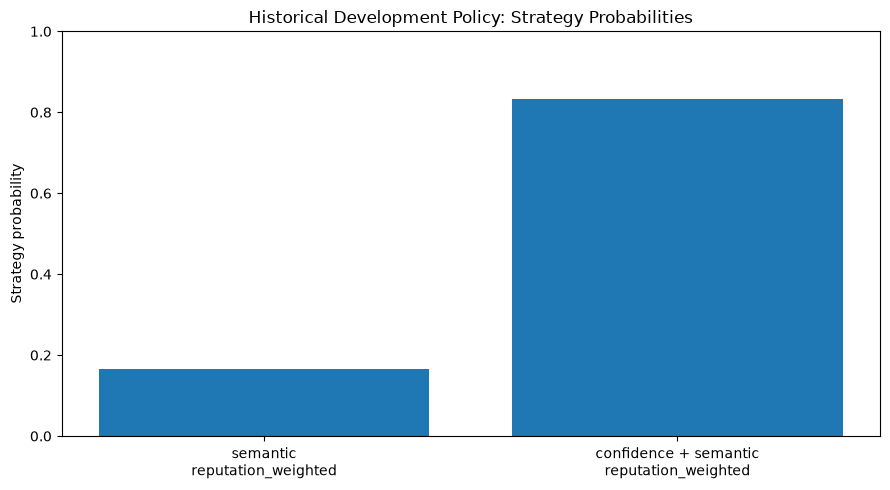

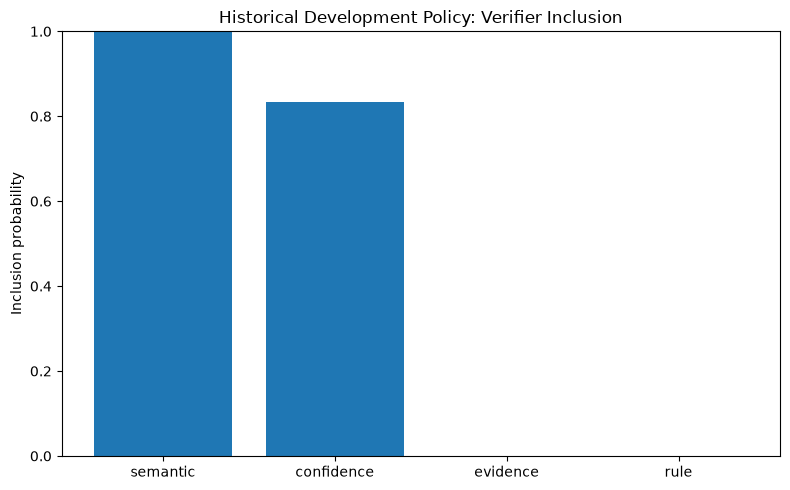

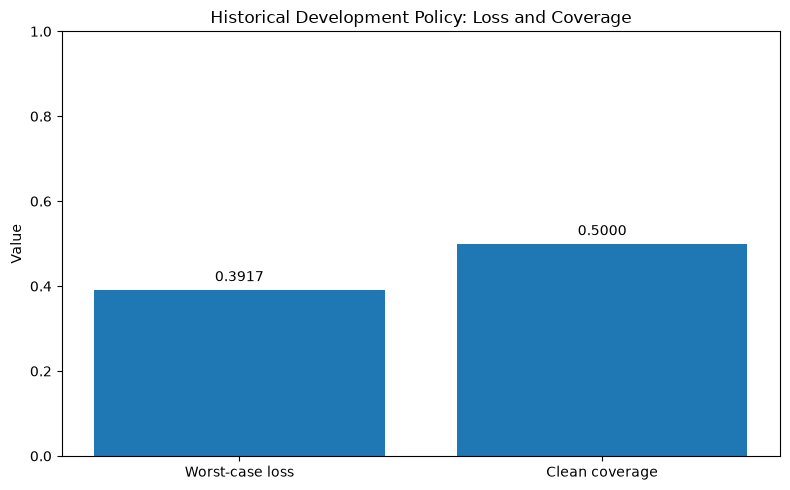

Graphs saved to: C:\Users\user\Desktop\Capstone stuff\capstone-backend\build\historical-policy-graphs
Game value: 0.39166666666666666
Coverage: 0.5
Expected estimated cost: 13792.685628331245
Verifier inclusion: {'semantic': 1.0, 'confidence': 0.8333333333333334, 'evidence': 0.0, 'rule': 0.0}


In [2]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

# Read only the already-saved policy
base = Path("artifacts/remaining-category-studies-v1/reference-50-v1/fit")
data = json.loads((base / "policy.json").read_text(encoding="utf-8"))

policy = data["policy"]
solution = policy["solution"]
strategies = policy["strategies"]
probabilities = dict(solution["probabilities"])

output = Path("build/historical-policy-graphs")
output.mkdir(parents=True, exist_ok=True)

# GRAPH 1: Strategy probabilities
active = [
    (s, probabilities.get(s["strategy_id"], 0))
    for s in strategies
    if probabilities.get(s["strategy_id"], 0) > 0
]

labels = [
    " + ".join(s["verifiers"]) + "\n" + s["aggregation"]
    for s, _ in active
]
values = [p for _, p in active]

plt.figure(figsize=(9, 5))
plt.bar(labels, values)
plt.ylabel("Strategy probability")
plt.title("Historical Development Policy: Strategy Probabilities")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(output / "01_strategy_probabilities.png", dpi=200)
plt.show()
plt.close()

# GRAPH 2: Verifier inclusion
verifiers = ["semantic", "confidence", "evidence", "rule"]

inclusion = {
    v: sum(
        probabilities.get(s["strategy_id"], 0)
        for s in strategies if v in s["verifiers"]
    )
    for v in verifiers
}

plt.figure(figsize=(8, 5))
plt.bar(inclusion.keys(), inclusion.values())
plt.ylabel("Inclusion probability")
plt.title("Historical Development Policy: Verifier Inclusion")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(output / "02_verifier_inclusion.png", dpi=200)
plt.show()
plt.close()

# GRAPH 3: Existing loss and coverage
loss = solution["game_value"]
coverage = solution["reliability_certificate"]["achieved_coverage"]
cost = solution["reliability_certificate"]["expected_cost"]

plt.figure(figsize=(8, 5))
bars = plt.bar(["Worst-case loss", "Clean coverage"], [loss, coverage])
plt.ylim(0, 1)
plt.ylabel("Value")
plt.title("Historical Development Policy: Loss and Coverage")

for bar, value in zip(bars, [loss, coverage]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(output / "03_loss_coverage_summary.png", dpi=200)
plt.show()
plt.close()

print("Graphs saved to:", output.resolve())
print("Game value:", loss)
print("Coverage:", coverage)
print("Expected estimated cost:", cost)
print("Verifier inclusion:", inclusion)

In [3]:
import json
from pathlib import Path

base = Path("artifacts/remaining-category-studies-v1/reference-50-v1/fit")
data = json.loads((base / "policy.json").read_text(encoding="utf-8"))

policy = data["policy"]
solution = policy["solution"]
strategies = policy["strategies"]
probabilities = dict(solution["probabilities"])

out = Path("build/historical-policy-graphs")
out.mkdir(parents=True, exist_ok=True)

# Export strategy probabilities
strategy_rows = []
for s in strategies:
    strategy_rows.append({
        "strategy_id": s["strategy_id"],
        "verifiers": ",".join(s["verifiers"]),
        "aggregation": s["aggregation"],
        "probability": probabilities.get(s["strategy_id"], 0.0),
    })

import csv

with (out / "strategy_probabilities.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=strategy_rows[0].keys())
    writer.writeheader()
    writer.writerows(strategy_rows)

# Export verifier inclusion
verifiers = ["semantic", "confidence", "evidence", "rule"]
inclusion = {
    v: sum(
        probabilities.get(s["strategy_id"], 0.0)
        for s in strategies if v in s["verifiers"]
    )
    for v in verifiers
}

with (out / "verifier_inclusion.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["verifier", "inclusion_probability"])
    writer.writerows(inclusion.items())

# Export existing solution metadata
metadata = {
    "source_study": "reference-50-v1",
    "status": "historical_descriptive_only",
    "game_value": solution["game_value"],
    "achieved_coverage": solution["reliability_certificate"]["achieved_coverage"],
    "expected_estimated_cost_ms": solution["reliability_certificate"]["expected_cost"],
    "verifier_inclusion": inclusion,
    "new_optimization_performed": False,
    "final_test_evaluated": False,
    "latency_distribution_available": False,
    "budget_sensitivity_curve_available": False,
}

(out / "run_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

print("Export completed:")
for file in sorted(out.iterdir()):
    print(file.name)

Export completed:
01_strategy_probabilities.png
02_verifier_inclusion.png
03_loss_coverage_summary.png
run_metadata.json
strategy_probabilities.csv
verifier_inclusion.csv
